# 3. Búsqueda en vecindarios grandes

La búsqueda en vecindarios grandes (*large neighborhood search*, LNS) mejora una solución completa repitiendo dos pasos. El primero destruye una parte de la solución, es decir, retira algunos de sus elementos; el segundo la repara, reinsertando esos elementos para obtener otra solución completa. El vecindario de una solución está formado por todas las soluciones que se pueden alcanzar con un par destruir–reparar, y es mucho más grande que el de un movimiento simple como el intercambio de dos posiciones. Este capítulo aplica el método a dos problemas de programación de producción que minimizan el tiempo total de terminación (*makespan*). El primero es el taller de flujo de permutación (*permutation flow shop*), donde la reparación inserta cada trabajo en su mejor posición. El segundo es el taller de trabajos (*job shop*), donde la reparación reinserta las operaciones al azar. En los dos casos el resultado se lee en un diagrama de Gantt, que muestra en qué intervalo de tiempo ocupa cada trabajo cada máquina.

## El esquema del método

Las dos implementaciones del capítulo siguen el mismo esquema. Se parte de una solución inicial $x$ y, en cada iteración, se aplican tres operaciones:

1. destruir, que retira de $x$ una fracción $\delta$ de sus elementos (el parámetro `destroy_size`);
2. reparar, que reinserta los elementos retirados y produce una solución completa $x'$;
3. aceptar, que decide si $x'$ reemplaza a $x$.

En las dos implementaciones el criterio de aceptación es de descenso, de modo que $x'$ reemplaza a $x$ solo si

$$C_{\max}(x') < C_{\max}(x),$$

donde $C_{\max}$ es el tiempo total de terminación. Con este criterio la búsqueda nunca empeora, y toda su capacidad de escapar de un óptimo local depende del tamaño del vecindario, que controla $\delta$. Un $\delta$ pequeño produce cambios locales; uno grande reconstruye buena parte de la solución en cada iteración.

In [1]:
import numpy as np
import random
import time
import matplotlib
import matplotlib.pyplot as plt
from copy import deepcopy
import matplotlib.patches as patches

## Taller de flujo de permutación

### El problema

Un taller de flujo tiene $n$ trabajos y $M$ máquinas. Todos los trabajos pasan por las máquinas en el mismo orden, de la máquina $0$ a la máquina $M-1$, y el trabajo $j$ ocupa la máquina $m$ durante un tiempo $p_{j,m}$. En la versión de permutación, los trabajos se procesan en el mismo orden en todas las máquinas, de modo que una solución es una permutación $\pi = (\pi_1, \dots, \pi_n)$ de los trabajos.

Dada la permutación, los tiempos de terminación $C_{j,m}$ (el trabajo en la posición $j$ de la secuencia, en la máquina $m$) se calculan por recurrencia. Un trabajo empieza en una máquina cuando se cumplen dos condiciones, que el mismo trabajo haya terminado en la máquina anterior y que la máquina haya terminado el trabajo anterior de la secuencia. Por eso

$$C_{1,0} = p_{\pi_1,0}, \qquad C_{1,m} = C_{1,m-1} + p_{\pi_1,m}, \qquad C_{j,0} = C_{j-1,0} + p_{\pi_j,0},$$

$$C_{j,m} = \max\left(C_{j,m-1},\, C_{j-1,m}\right) + p_{\pi_j,m},$$

y el tiempo total de terminación es el del último trabajo en la última máquina, $C_{\max} = C_{n,M-1}$. El método `calcular_makespan` implementa esta recurrencia. Con `guardar_tiempos=True` guarda además los tiempos de inicio y de fin de cada operación, que son los que necesita el diagrama de Gantt.

### Destrucción, reparación y aceptación

El método `destruir` retira

$$d = \max\left(1,\, \lfloor n\,\delta \rfloor\right)$$

trabajos escogidos al azar y devuelve la secuencia parcial con los trabajos restantes en su orden original. Los trabajos retirados quedan en una lista ordenada según la posición que ocupaban.

El método `reparar_greedy` es una reparación voraz por inserción. Toma los trabajos retirados uno por uno y, para cada uno, prueba todas las posiciones de la secuencia parcial, calcula el tiempo total de terminación de cada prueba y lo inserta en la posición con el menor valor. Cada trabajo se inserta antes de pasar al siguiente, así que las pruebas del segundo trabajo ya incluyen al primero.

El método `ejecutar` genera `num_soluciones_iniciales` permutaciones aleatorias y se queda con la mejor. En cada iteración destruye y repara la mejor solución conocida y la reemplaza si la nueva es estrictamente mejor. En esta implementación no hay una solución actual distinta de la mejor, de modo que la búsqueda es un descenso que siempre parte de la mejor secuencia encontrada.

El curso tenía dos versiones de este código. La segunda agrega el cálculo de los tiempos de inicio y de fin y el diagrama de Gantt sin cambiar el algoritmo, y es la que se usa aquí.

In [2]:
class LNS_Flowshop:
    """
    Implementación de Large Neighborhood Search (LNS) para el problema de Flowshop
    """
    def __init__(self, tiempos_procesamiento, num_trabajos, num_maquinas,
                 max_iter=100, destroy_size=0.3, num_soluciones_iniciales=10):
        """
        Inicializa el algoritmo LNS para Flowshop

        Parámetros:
        - tiempos_procesamiento: matriz de tiempos de procesamiento [trabajo][máquina]
        - num_trabajos: número de trabajos
        - num_maquinas: número de máquinas
        - max_iter: número máximo de iteraciones
        - destroy_size: proporción de la solución a destruir en cada iteración
        - num_soluciones_iniciales: número de soluciones iniciales a generar
        """
        self.tiempos_procesamiento = tiempos_procesamiento
        self.num_trabajos = num_trabajos
        self.num_maquinas = num_maquinas
        self.max_iter = max_iter
        self.destroy_size = destroy_size
        self.num_soluciones_iniciales = num_soluciones_iniciales

        # Variables para almacenar la mejor solución
        self.mejor_solucion = None
        self.mejor_makespan = float('inf')

        # Historial para seguimiento de la convergencia
        self.historial_makespan = []

        # Para almacenar los tiempos de inicio y fin de cada trabajo en cada máquina
        self.tiempos_inicio_fin = None

    def generar_solucion_inicial(self):
        """Genera una secuencia aleatoria de trabajos"""
        return np.random.permutation(self.num_trabajos).tolist()

    def calcular_makespan(self, secuencia, guardar_tiempos=False):
        """
        Calcula el makespan (tiempo total) para una secuencia dada de trabajos

        Si guardar_tiempos es True, guarda los tiempos de inicio y fin de cada trabajo en cada máquina
        """
        # Inicializar matriz de tiempos de finalización
        tiempos = np.zeros((len(secuencia), self.num_maquinas))

        # Si se requiere guardar los tiempos, inicializar matrices de inicio y fin
        if guardar_tiempos:
            tiempos_inicio = np.zeros((len(secuencia), self.num_maquinas))
            tiempos_fin = np.zeros((len(secuencia), self.num_maquinas))

        # Calcular tiempo para el primer trabajo en todas las máquinas
        for m in range(self.num_maquinas):
            if m == 0:
                if guardar_tiempos:
                    tiempos_inicio[0][m] = 0
                tiempos[0][m] = self.tiempos_procesamiento[secuencia[0]][m]
            else:
                if guardar_tiempos:
                    tiempos_inicio[0][m] = tiempos[0][m-1]
                tiempos[0][m] = tiempos[0][m-1] + self.tiempos_procesamiento[secuencia[0]][m]

            if guardar_tiempos:
                tiempos_fin[0][m] = tiempos[0][m]

        # Calcular tiempos para el resto de trabajos
        for j in range(1, len(secuencia)):
            for m in range(self.num_maquinas):
                if m == 0:
                    if guardar_tiempos:
                        tiempos_inicio[j][m] = tiempos[j-1][m]
                    tiempos[j][m] = tiempos[j-1][m] + self.tiempos_procesamiento[secuencia[j]][m]
                else:
                    tiempo_anterior_maquina = tiempos[j][m-1]
                    tiempo_anterior_trabajo = tiempos[j-1][m]
                    if guardar_tiempos:
                        tiempos_inicio[j][m] = max(tiempo_anterior_maquina, tiempo_anterior_trabajo)
                    tiempos[j][m] = max(tiempo_anterior_maquina, tiempo_anterior_trabajo) + self.tiempos_procesamiento[secuencia[j]][m]

                if guardar_tiempos:
                    tiempos_fin[j][m] = tiempos[j][m]

        # Si se requiere guardar los tiempos, almacenarlos junto con la secuencia
        if guardar_tiempos:
            self.tiempos_inicio_fin = {
                'secuencia': secuencia,
                'inicio': tiempos_inicio,
                'fin': tiempos_fin
            }

        # El makespan es el tiempo de finalización del último trabajo en la última máquina
        return tiempos[-1][-1]

    def destruir(self, solucion):
        """
        Destruye parte de la solución eliminando algunos trabajos
        """
        num_a_eliminar = max(1, int(len(solucion) * self.destroy_size))
        indices_a_eliminar = random.sample(range(len(solucion)), num_a_eliminar)
        trabajos_eliminados = [solucion[i] for i in sorted(indices_a_eliminar)]
        solucion_parcial = [j for i, j in enumerate(solucion) if i not in indices_a_eliminar]

        return solucion_parcial, trabajos_eliminados

    def reparar_greedy(self, solucion_parcial, trabajos_eliminados):
        """
        Repara la solución insertando los trabajos eliminados en la mejor posición
        """
        solucion_actual = solucion_parcial.copy()

        for trabajo in trabajos_eliminados:
            mejor_posicion = 0
            mejor_makespan = float('inf')

            # Probar insertar el trabajo en cada posición posible
            for pos in range(len(solucion_actual) + 1):
                solucion_prueba = solucion_actual.copy()
                solucion_prueba.insert(pos, trabajo)
                makespan = self.calcular_makespan(solucion_prueba)

                if makespan < mejor_makespan:
                    mejor_makespan = makespan
                    mejor_posicion = pos

            # Insertar el trabajo en la mejor posición encontrada
            solucion_actual.insert(mejor_posicion, trabajo)

        return solucion_actual

    def ejecutar(self):
        """
        Ejecuta el algoritmo LNS
        """
        # Generar múltiples soluciones iniciales y quedarse con la mejor
        for _ in range(self.num_soluciones_iniciales):
            solucion_inicial = self.generar_solucion_inicial()
            makespan_inicial = self.calcular_makespan(solucion_inicial)

            if makespan_inicial < self.mejor_makespan:
                self.mejor_solucion = solucion_inicial
                self.mejor_makespan = makespan_inicial

        print(f"Solución inicial: {self.mejor_solucion}")
        print(f"Makespan inicial: {self.mejor_makespan:.2f}")

        # Guardar el makespan inicial en el historial
        self.historial_makespan.append(self.mejor_makespan)

        # Iteraciones principales del algoritmo
        for i in range(self.max_iter):
            # Destruir parte de la mejor solución actual
            solucion_parcial, trabajos_eliminados = self.destruir(self.mejor_solucion)

            # Reparar la solución
            nueva_solucion = self.reparar_greedy(solucion_parcial, trabajos_eliminados)
            nuevo_makespan = self.calcular_makespan(nueva_solucion)

            # Actualizar la mejor solución si se encontró una mejor
            if nuevo_makespan < self.mejor_makespan:
                self.mejor_solucion = nueva_solucion
                self.mejor_makespan = nuevo_makespan

            # Guardar el makespan actual en el historial
            self.historial_makespan.append(self.mejor_makespan)

            # Imprimir progreso
            if (i+1) % 10 == 0:
                print(f"Iteración {i+1}/{self.max_iter}, Mejor Makespan: {self.mejor_makespan:.2f}")

        # Calcular los tiempos de inicio y fin para la mejor solución encontrada
        self.calcular_makespan(self.mejor_solucion, guardar_tiempos=True)

Los dos métodos siguientes muestran los resultados. `mostrar_resultados` imprime la mejor secuencia, grafica la evolución del mejor tiempo total de terminación y llama a `mostrar_diagrama_gantt`. En el diagrama cada fila es una máquina y cada rectángulo es un trabajo, dibujado desde su tiempo de inicio hasta su tiempo de fin y rotulado con su número. Se definen aparte de la clase para separar el algoritmo de su presentación, y se agregan a ella al final de la celda.

In [3]:
def mostrar_resultados(self):
    """
    Muestra los resultados finales y gráfica de convergencia
    """
    print("\nResultados finales:")
    print(f"Mejor secuencia encontrada: {self.mejor_solucion}")
    print(f"Makespan: {self.mejor_makespan:.2f}")

    # Graficar convergencia
    plt.figure(figsize=(9, 4.5))
    plt.plot(range(len(self.historial_makespan)), self.historial_makespan, 'b-')
    plt.title('Convergencia del algoritmo LNS para el taller de flujo')
    plt.xlabel('Iteración')
    plt.ylabel('Tiempo total de terminación')
    plt.grid(True)
    plt.show()

    # Graficar diagrama de Gantt
    self.mostrar_diagrama_gantt()

def mostrar_diagrama_gantt(self):
    """
    Muestra un diagrama de Gantt con la planificación de trabajos en máquinas
    """
    if self.tiempos_inicio_fin is None:
        print("No hay datos disponibles para generar el diagrama de Gantt")
        return

    # Colores para los diferentes trabajos
    colores = plt.cm.tab20.colors

    fig, ax = plt.subplots(figsize=(12, 6))

    # Para cada máquina y cada trabajo
    for m in range(self.num_maquinas):
        for j, trabajo_id in enumerate(self.tiempos_inicio_fin['secuencia']):
            inicio = self.tiempos_inicio_fin['inicio'][j][m]
            fin = self.tiempos_inicio_fin['fin'][j][m]
            duracion = fin - inicio

            # Crear un rectángulo para representar el trabajo en la máquina
            rect = patches.Rectangle(
                (inicio, self.num_maquinas - m - 1),  # (x, y)
                duracion,  # ancho
                0.8,  # alto
                linewidth=1,
                edgecolor='black',
                facecolor=colores[trabajo_id % len(colores)],
                alpha=0.7,
                label=f'Trabajo {trabajo_id}' if m == 0 else ""  # Solo etiqueta una vez
            )
            ax.add_patch(rect)

            # Añadir texto con el ID del trabajo
            ax.text(
                inicio + duracion/2,
                self.num_maquinas - m - 1 + 0.4,
                f'{trabajo_id}',
                ha='center',
                va='center',
                fontsize=9,
                color='black'
            )

    # Configurar ejes y etiquetas
    ax.set_xlim(0, self.mejor_makespan * 1.05)
    ax.set_ylim(0, self.num_maquinas)
    ax.set_yticks([m + 0.4 for m in range(self.num_maquinas)])
    ax.set_yticklabels([f'Máquina {self.num_maquinas - m - 1}' for m in range(self.num_maquinas)])
    ax.set_xlabel('Tiempo')
    ax.set_title('Diagrama de Gantt - Planificación de trabajos en máquinas')
    ax.grid(True, axis='x', linestyle='--', alpha=0.7)

    # Manejar leyenda sin duplicados
    handles, labels = [], []
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h)
            labels.append(l)

    # Colocar leyenda fuera del diagrama
    if handles:
        ax.legend(
            handles=handles,
            labels=labels,
            loc='upper center',
            bbox_to_anchor=(0.5, -0.1),
            ncol=min(10, len(handles))
        )

    plt.tight_layout()
    plt.show()

LNS_Flowshop.mostrar_resultados = mostrar_resultados
LNS_Flowshop.mostrar_diagrama_gantt = mostrar_diagrama_gantt

### Ejemplo con 20 trabajos y 5 máquinas

La instancia tiene 20 trabajos y 5 máquinas, con tiempos de procesamiento enteros aleatorios entre 1 y 99. El algoritmo hace 100 iteraciones con $\delta = 0{,}3$, de modo que cada iteración retira y reinserta $d = \lfloor 20 \times 0{,}3 \rfloor = 6$ trabajos, y parte de la mejor de 10 permutaciones aleatorias.

In [4]:
# Generar un problema de ejemplo
num_trabajos = 20
num_maquinas = 5

# Generar tiempos de procesamiento aleatorios
np.random.seed(42)  # Para reproducibilidad
random.seed(42)
tiempos_procesamiento = np.random.randint(1, 100, size=(num_trabajos, num_maquinas))

print(f"Problema de Flowshop con {num_trabajos} trabajos y {num_maquinas} máquinas")

# Crear y ejecutar el algoritmo LNS
inicio = time.time()
lns = LNS_Flowshop(
    tiempos_procesamiento=tiempos_procesamiento,
    num_trabajos=num_trabajos,
    num_maquinas=num_maquinas,
    max_iter=100,
    destroy_size=0.3,
    num_soluciones_iniciales=10
)

lns.ejecutar()
fin = time.time()

Problema de Flowshop con 20 trabajos y 5 máquinas
Solución inicial: [7, 9, 0, 8, 18, 13, 1, 11, 5, 2, 14, 17, 10, 12, 15, 19, 4, 3, 16, 6]
Makespan inicial: 1445.00
Iteración 10/100, Mejor Makespan: 1308.00
Iteración 20/100, Mejor Makespan: 1308.00
Iteración 30/100, Mejor Makespan: 1308.00
Iteración 40/100, Mejor Makespan: 1308.00
Iteración 50/100, Mejor Makespan: 1308.00


Iteración 60/100, Mejor Makespan: 1308.00
Iteración 70/100, Mejor Makespan: 1308.00
Iteración 80/100, Mejor Makespan: 1308.00
Iteración 90/100, Mejor Makespan: 1308.00
Iteración 100/100, Mejor Makespan: 1308.00



Resultados finales:
Mejor secuencia encontrada: [7, 4, 15, 11, 5, 10, 13, 2, 18, 6, 1, 17, 8, 14, 9, 19, 16, 0, 12, 3]
Makespan: 1308.00


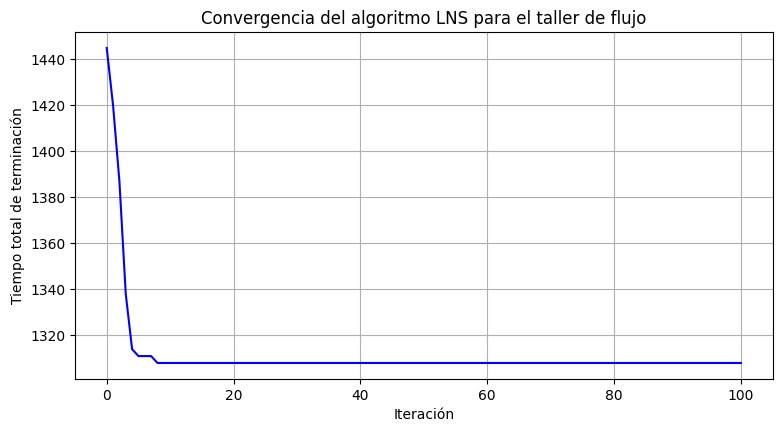

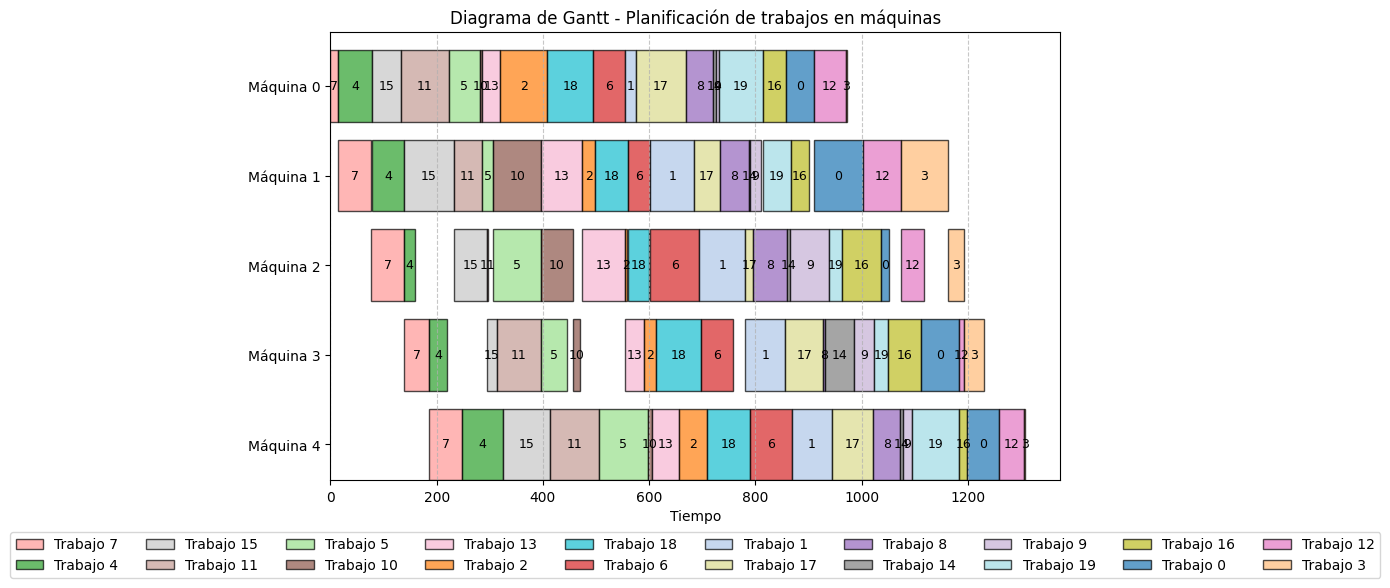

Tiempo de ejecución: 0.39 segundos


In [5]:
# Mostrar resultados
lns.mostrar_resultados()
print(f"Tiempo de ejecución: {fin - inicio:.2f} segundos")

El tiempo total de terminación baja en las primeras diez iteraciones y después no vuelve a cambiar. Como la búsqueda siempre destruye y repara la mejor secuencia y solo acepta mejoras estrictas, en el resto de las iteraciones ninguna de las reparaciones probadas mejora esa secuencia.

El diagrama de Gantt muestra la estructura de un taller de flujo de permutación. Los trabajos aparecen en el mismo orden en las cinco máquinas, y la máquina 0 trabaja sin interrupciones, porque cada trabajo empieza en ella apenas termina el anterior. En las máquinas siguientes aparecen intervalos vacíos, en los que la máquina espera a que el trabajo siguiente salga de la máquina anterior. El tiempo total de terminación es el instante en que el último trabajo de la secuencia sale de la máquina 4.

## Taller de trabajos

### El problema

En un taller de trabajos cada trabajo tiene su propia ruta. El trabajo $j$ es una lista ordenada de operaciones $(m_{j,0}, p_{j,0}), (m_{j,1}, p_{j,1}), \dots$, donde la operación $i$ debe hacerse en la máquina $m_{j,i}$ durante un tiempo $p_{j,i}$, y no puede empezar antes de que termine la operación $i-1$ del mismo trabajo. Cada máquina procesa una operación a la vez. La decisión es el orden de las operaciones en cada máquina, y el objetivo es otra vez minimizar el tiempo total de terminación.

### Representación y evaluación

Una solución es una lista con una secuencia por máquina. La secuencia de la máquina $m$ contiene los pares `(id_trabajo, id_operacion)` de todas las operaciones que se hacen en ella, en el orden en que se procesan. La clase `Trabajo` guarda la ruta de cada trabajo y los tiempos de inicio $s_{j,i}$ de sus operaciones.

No toda lista de secuencias es un programa posible. Si la máquina 0 debe procesar primero la segunda operación del trabajo A y la máquina 1 debe procesar primero la segunda operación del trabajo B, pero la primera operación de A está detrás en la máquina 1 y la de B está detrás en la máquina 0, cada máquina espera una operación que la otra no puede hacer todavía. Las secuencias son incompatibles y no existe un programa que las cumpla.

El método `evaluar_solucion` construye el programa respetando las dos condiciones del problema y detecta ese caso. Lleva, para cada máquina, la siguiente posición por programar de su secuencia y, para cada trabajo, la siguiente operación por programar de su ruta. Recorre las máquinas una y otra vez, y en cada una programa las operaciones de su secuencia mientras la siguiente sea también la siguiente de su trabajo, es decir, mientras la operación anterior del mismo trabajo ya esté programada. Cada operación empieza en

$$s_{j,i} = \max\left(T_m,\; F_j\right),$$

donde $T_m$ es el instante en que la máquina $m$ quedó libre y $F_j$ el instante en que terminó la operación anterior del trabajo $j$ ($F_j = 0$ para la primera). Después actualiza $T_m = F_j = s_{j,i} + p_{j,i}$. Cuando todas las operaciones quedan programadas, el tiempo total de terminación es $C_{\max} = \max_m T_m$. Si en un recorrido completo ninguna máquina puede programar una operación, las secuencias son incompatibles y el método devuelve $C_{\max} = \infty$.

El método también evalúa soluciones parciales, a las que les faltan algunas operaciones. En ese caso la operación anterior de un trabajo es la anterior entre las que están en la solución. Esto lo usa la reparación para comprobar cada inserción.

### Destrucción, reparación y aceptación

El método `destruir` trabaja máquina por máquina. En la máquina $m$, con $n_m$ operaciones, retira

$$d_m = \max\left(1,\, \lfloor n_m\,\delta \rfloor\right)$$

operaciones escogidas al azar y guarda cada una junto con su máquina. Retirar operaciones de una solución factible deja una solución parcial factible.

El método `reparar` reinserta las operaciones retiradas una por una. Para cada operación prueba las posiciones de la secuencia de su máquina en un orden al azar y la deja en la primera con la que la solución parcial sigue siendo factible. Siempre existe al menos una posición así. A diferencia del taller de flujo, la reparación no compara el tiempo total de terminación de las posiciones, de modo que todo el trabajo de mejora recae en el criterio de aceptación.

El método `ejecutar` parte de una solución aleatoria factible. Para construirla, baraja una lista en la que cada trabajo aparece tantas veces como operaciones tiene, de modo que la $k$-ésima aparición del trabajo $j$ representa su operación $k$. Al recorrer la lista, cada operación se agrega al final de la secuencia de su máquina. Como las operaciones de un trabajo entran en el orden de su ruta, las secuencias que resultan siempre son compatibles. Asignar a cada máquina un orden al azar, en cambio, suele producir secuencias incompatibles. En cada iteración, el método destruye y repara la solución actual y acepta la candidata solo si su tiempo total de terminación es estrictamente menor. La mejor solución global se actualiza cuando mejora la actual, así que con este criterio las dos coinciden.

In [6]:
class Trabajo:
    def __init__(self, id, operaciones):
        self.id = id
        self.operaciones = operaciones  # Lista de tuplas (máquina, tiempo)
        self.inicio_ops = [0] * len(operaciones)  # Tiempo de inicio de cada operación

In [7]:
class LNS_JobShop:
    def __init__(self, trabajos, num_maquinas, max_iter=100, destroy_size=0.2):
        self.trabajos = trabajos
        self.num_maquinas = num_maquinas
        self.max_iter = max_iter
        self.destroy_size = destroy_size
        self.mejor_solucion = None
        self.mejor_makespan = float('inf')
        self.historial_makespan = []

    def generar_solucion_inicial(self):
        # Crear una solución inicial aleatoria y factible:
        # cada trabajo aparece en la lista tantas veces como operaciones tiene,
        # y su k-ésima aparición corresponde a su k-ésima operación
        orden = [j for j, trabajo in enumerate(self.trabajos) for _ in trabajo.operaciones]
        random.shuffle(orden)

        solucion = [[] for _ in range(self.num_maquinas)]
        siguiente_op = [0] * len(self.trabajos)
        for j in orden:
            i = siguiente_op[j]
            maquina = self.trabajos[j].operaciones[i][0]
            solucion[maquina].append((j, i))  # (id_trabajo, id_operacion)
            siguiente_op[j] += 1
        return solucion

    def evaluar_solucion(self, solucion):
        # Reiniciar tiempos de inicio
        for trabajo in self.trabajos:
            trabajo.inicio_ops = [0] * len(trabajo.operaciones)

        # Operaciones de cada trabajo que están en la solución, en su orden.
        # En una solución parcial (durante la reparación) pueden faltar algunas.
        presentes = [[] for _ in self.trabajos]
        for ops_maquina in solucion:
            for j, i in ops_maquina:
                presentes[j].append(i)
        for lista in presentes:
            lista.sort()

        tiempo_maquinas = [0] * self.num_maquinas  # Fin de la última operación de cada máquina
        fin_trabajo = [0] * len(self.trabajos)     # Fin de la última operación programada de cada trabajo
        puntero = [0] * len(self.trabajos)         # Siguiente operación por programar de cada trabajo
        posicion = [0] * self.num_maquinas         # Siguiente posición por programar de cada máquina
        pendientes = sum(len(ops_maquina) for ops_maquina in solucion)

        # Recorrer las máquinas hasta programar todas las operaciones
        while pendientes > 0:
            avance = False
            for m, ops_maquina in enumerate(solucion):
                while posicion[m] < len(ops_maquina):
                    j, i = ops_maquina[posicion[m]]

                    # Solo se programa si la operación anterior del mismo trabajo ya terminó de programarse
                    if presentes[j][puntero[j]] != i:
                        break

                    duracion = self.trabajos[j].operaciones[i][1]
                    inicio = max(tiempo_maquinas[m], fin_trabajo[j])

                    # Actualizar tiempos
                    self.trabajos[j].inicio_ops[i] = inicio
                    tiempo_maquinas[m] = inicio + duracion
                    fin_trabajo[j] = inicio + duracion
                    puntero[j] += 1
                    posicion[m] += 1
                    pendientes -= 1
                    avance = True

            # Si ninguna máquina pudo avanzar, las secuencias son incompatibles
            if not avance:
                return float('inf')

        # El makespan es el tiempo máximo de finalización
        makespan = max(tiempo_maquinas)
        return makespan

    def destruir(self, solucion):
        # Seleccionar aleatoriamente algunas operaciones para destruir
        solucion_destruida = [lista[:] for lista in solucion]
        ops_destruidas = []

        for m in range(self.num_maquinas):
            num_ops = len(solucion[m])
            if num_ops > 0:
                num_destruir = max(1, int(num_ops * self.destroy_size))
                indices_destruir = random.sample(range(num_ops), num_destruir)

                # Extraer operaciones en orden inverso para no afectar índices
                for idx in sorted(indices_destruir, reverse=True):
                    ops_destruidas.append((m, solucion_destruida[m].pop(idx)))

        return solucion_destruida, ops_destruidas

    def reparar(self, solucion_destruida, ops_destruidas):
        # Reinsertar operaciones destruidas en posiciones aleatorias que dejen la solución factible
        solucion_reparada = [lista[:] for lista in solucion_destruida]

        for m, op in ops_destruidas:
            posiciones = list(range(len(solucion_reparada[m]) + 1))
            random.shuffle(posiciones)
            for pos in posiciones:
                solucion_reparada[m].insert(pos, op)
                if self.evaluar_solucion(solucion_reparada) < float('inf'):
                    break
                solucion_reparada[m].pop(pos)

        return solucion_reparada

    def ejecutar(self):
        # Generar solución inicial
        solucion_actual = self.generar_solucion_inicial()
        makespan_actual = self.evaluar_solucion(solucion_actual)

        self.mejor_solucion = [lista[:] for lista in solucion_actual]
        self.mejor_makespan = makespan_actual

        print(f"Makespan inicial: {makespan_actual}")
        self.historial_makespan.append(makespan_actual)

        # Iteraciones principales
        for i in range(self.max_iter):
            # Destruir parte de la solución
            solucion_destruida, ops_destruidas = self.destruir(solucion_actual)

            # Reparar la solución
            solucion_candidata = self.reparar(solucion_destruida, ops_destruidas)

            # Evaluar la solución candidata
            makespan_candidato = self.evaluar_solucion(solucion_candidata)

            # Aceptar si es mejor
            if makespan_candidato < makespan_actual:
                solucion_actual = [lista[:] for lista in solucion_candidata]
                makespan_actual = makespan_candidato

                # Actualizar mejor solución global
                if makespan_actual < self.mejor_makespan:
                    self.mejor_solucion = [lista[:] for lista in solucion_actual]
                    self.mejor_makespan = makespan_actual

            self.historial_makespan.append(self.mejor_makespan)

            if (i+1) % 10 == 0:
                print(f"Iteración {i+1}/{self.max_iter}, Mejor makespan: {self.mejor_makespan}")

Igual que en el taller de flujo, los métodos de presentación van en una celda aparte. `mostrar_resultados` vuelve a evaluar la mejor solución, para que los tiempos de inicio guardados en cada `Trabajo` correspondan a ella, y luego grafica la convergencia y el diagrama de Gantt. En este diagrama cada rectángulo es una operación, con el color y el rótulo de su trabajo.

In [8]:
def mostrar_resultados(self):
    print("\nResultados finales:")
    print(f"Mejor makespan encontrado: {self.mejor_makespan}")

    # Evaluar la mejor solución para actualizar los tiempos de inicio
    self.evaluar_solucion(self.mejor_solucion)

    # Graficar convergencia
    plt.figure(figsize=(9, 4.5))
    plt.plot(range(len(self.historial_makespan)), self.historial_makespan, 'b-')
    plt.title('Convergencia del algoritmo LNS para el taller de trabajos')
    plt.xlabel('Iteración')
    plt.ylabel('Tiempo total de terminación')
    plt.grid(True)
    plt.show()

    # Mostrar diagrama de Gantt
    self.mostrar_gantt()

def mostrar_gantt(self):
    fig, ax = plt.subplots(figsize=(11, 5.5))

    # Crear un mapa de colores personalizado
    colores = matplotlib.colormaps['tab20'].resampled(len(self.trabajos))

    # Para cada trabajo, dibujar sus operaciones
    for j, trabajo in enumerate(self.trabajos):
        for i, (maquina, duracion) in enumerate(trabajo.operaciones):
            inicio = trabajo.inicio_ops[i]
            ax.barh(maquina, duracion, left=inicio, height=0.5,
                   color=colores(j), alpha=0.8,
                   edgecolor='black', linewidth=1)

            # Añadir etiqueta
            ax.text(inicio + duracion/2, maquina, f'T{j}',
                   ha='center', va='center', color='black', fontweight='bold')

    # Configurar ejes
    ax.set_yticks(range(self.num_maquinas))
    ax.set_yticklabels([f'Máquina {i}' for i in range(self.num_maquinas)])
    ax.set_xlabel('Tiempo')
    ax.set_ylabel('Máquinas')
    ax.set_title('Diagrama de Gantt - Programación del taller de trabajos')
    ax.grid(True, axis='x', linestyle='--', alpha=0.7)

    # Añadir leyenda
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=colores(j), edgecolor='black', label=f'Trabajo {j}')
                      for j in range(len(self.trabajos))]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.01, 1))

    plt.tight_layout()
    plt.show()

LNS_JobShop.mostrar_resultados = mostrar_resultados
LNS_JobShop.mostrar_gantt = mostrar_gantt

### Ejemplo con 3 trabajos y 3 máquinas

El primer ejemplo es una instancia pequeña, escrita a mano, en la que cada trabajo pasa una vez por cada máquina. La búsqueda hace 100 iteraciones con $\delta = 0{,}3$. Como cada máquina tiene tres operaciones, $\lfloor 3 \times 0{,}3 \rfloor = 0$ y el mínimo de la fórmula hace que se retire una operación por máquina en cada iteración.

In [9]:
random.seed(42)
np.random.seed(42)

# Definir un problema de ejemplo: (máquina, tiempo)
# 3 trabajos, 3 máquinas
trabajos = [
    Trabajo(0, [(0, 3), (1, 2), (2, 2)]),  # Trabajo 0
    Trabajo(1, [(0, 2), (2, 1), (1, 4)]),  # Trabajo 1
    Trabajo(2, [(1, 4), (0, 3), (2, 3)])   # Trabajo 2
]

# Crear y ejecutar el algoritmo LNS
lns = LNS_JobShop(trabajos, num_maquinas=3, max_iter=100, destroy_size=0.3)

tiempo_inicio = time.time()
lns.ejecutar()
tiempo_fin = time.time()

print(f"\nTiempo de ejecución: {tiempo_fin - tiempo_inicio:.2f} segundos")

Makespan inicial: 14
Iteración 10/100, Mejor makespan: 13
Iteración 20/100, Mejor makespan: 13
Iteración 30/100, Mejor makespan: 13
Iteración 40/100, Mejor makespan: 13
Iteración 50/100, Mejor makespan: 12
Iteración 60/100, Mejor makespan: 12
Iteración 70/100, Mejor makespan: 12
Iteración 80/100, Mejor makespan: 12
Iteración 90/100, Mejor makespan: 12
Iteración 100/100, Mejor makespan: 12

Tiempo de ejecución: 0.00 segundos



Resultados finales:
Mejor makespan encontrado: 12


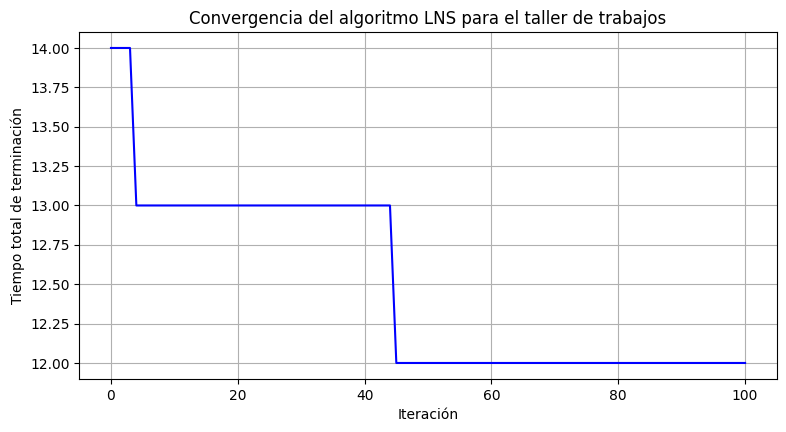

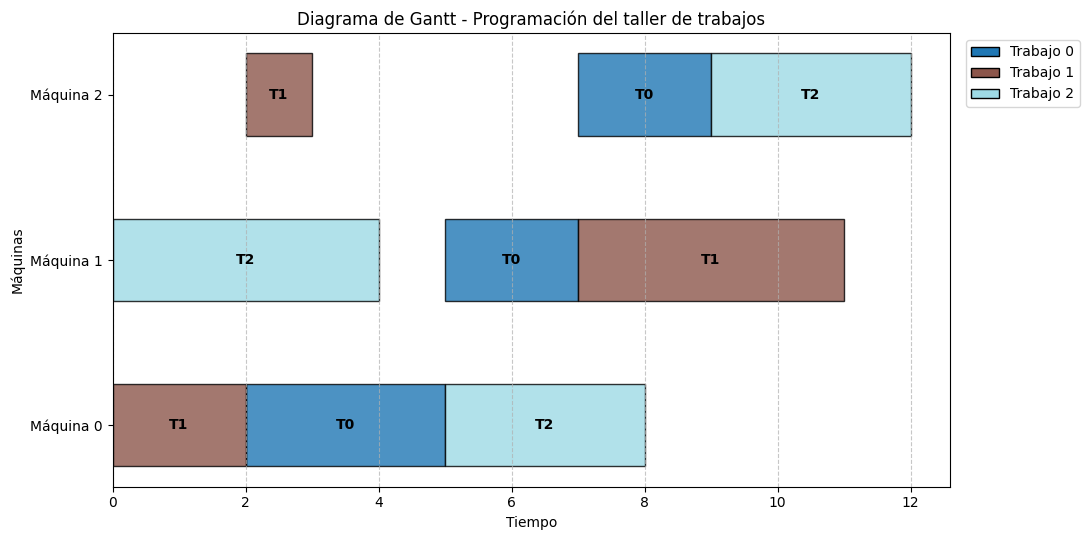

In [10]:
lns.mostrar_resultados()

La búsqueda baja el tiempo total de terminación de 14 a 12. En esta instancia ningún programa puede terminar antes del instante 10, porque las tres operaciones del trabajo 2 suman 10 unidades de tiempo, y lo mismo ocurre con la carga de la máquina 1. En el diagrama se ve que la operación de cada trabajo en una máquina empieza solo cuando terminó la anterior de su ruta.

### Ejemplo con 6 trabajos y 6 máquinas

El segundo ejemplo genera una instancia aleatoria de 6 trabajos y 6 máquinas. La ruta de cada trabajo es una permutación aleatoria de las máquinas, de modo que cada trabajo pasa una vez por cada una, y los tiempos de procesamiento son enteros entre 1 y 10. La búsqueda hace 200 iteraciones con $\delta = 0{,}2$, lo que retira una operación por máquina en cada iteración.

In [11]:
random.seed(42)
np.random.seed(42)

# Problema más grande: 6 trabajos, 6 máquinas
print("Resolviendo problema más grande (6x6)...")

# Generar un problema aleatorio más grande
num_trabajos = 6
num_maquinas = 6
trabajos_grandes = []

for j in range(num_trabajos):
    # Crear una secuencia de operaciones que pase por todas las máquinas
    maquinas = list(range(num_maquinas))
    random.shuffle(maquinas)
    operaciones = [(m, random.randint(1, 10)) for m in maquinas]
    trabajos_grandes.append(Trabajo(j, operaciones))

for t in trabajos_grandes:
    print(f"Trabajo {t.id}: {t.operaciones}")

# Resolver el problema grande
lns_grande = LNS_JobShop(trabajos_grandes, num_maquinas=num_maquinas, max_iter=200, destroy_size=0.2)

tiempo_inicio = time.time()
lns_grande.ejecutar()
tiempo_fin = time.time()

print(f"\nTiempo de ejecución: {tiempo_fin - tiempo_inicio:.2f} segundos")

Resolviendo problema más grande (6x6)...
Trabajo 0: [(3, 4), (1, 4), (2, 3), (4, 2), (0, 9), (5, 2)]
Trabajo 1: [(1, 4), (2, 4), (5, 9), (0, 10), (3, 1), (4, 9)]
Trabajo 2: [(2, 10), (5, 5), (0, 1), (3, 3), (4, 7), (1, 6)]
Trabajo 3: [(5, 2), (0, 7), (3, 2), (4, 6), (1, 6), (2, 10)]
Trabajo 4: [(1, 7), (4, 2), (5, 9), (3, 5), (0, 10), (2, 6)]
Trabajo 5: [(5, 5), (2, 2), (3, 4), (0, 2), (1, 7), (4, 5)]
Makespan inicial: 81
Iteración 10/200, Mejor makespan: 79
Iteración 20/200, Mejor makespan: 79
Iteración 30/200, Mejor makespan: 79
Iteración 40/200, Mejor makespan: 79
Iteración 50/200, Mejor makespan: 79
Iteración 60/200, Mejor makespan: 79
Iteración 70/200, Mejor makespan: 79
Iteración 80/200, Mejor makespan: 79
Iteración 90/200, Mejor makespan: 71
Iteración 100/200, Mejor makespan: 71
Iteración 110/200, Mejor makespan: 71
Iteración 120/200, Mejor makespan: 71
Iteración 130/200, Mejor makespan: 71
Iteración 140/200, Mejor makespan: 71
Iteración 150/200, Mejor makespan: 71
Iteración 160


Resultados finales:
Mejor makespan encontrado: 69


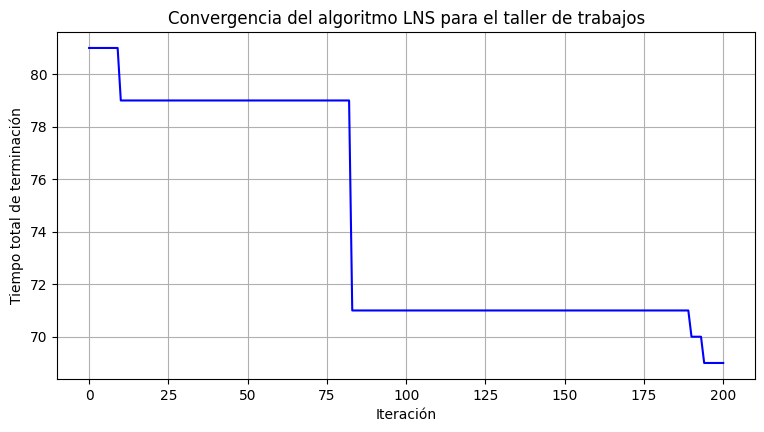

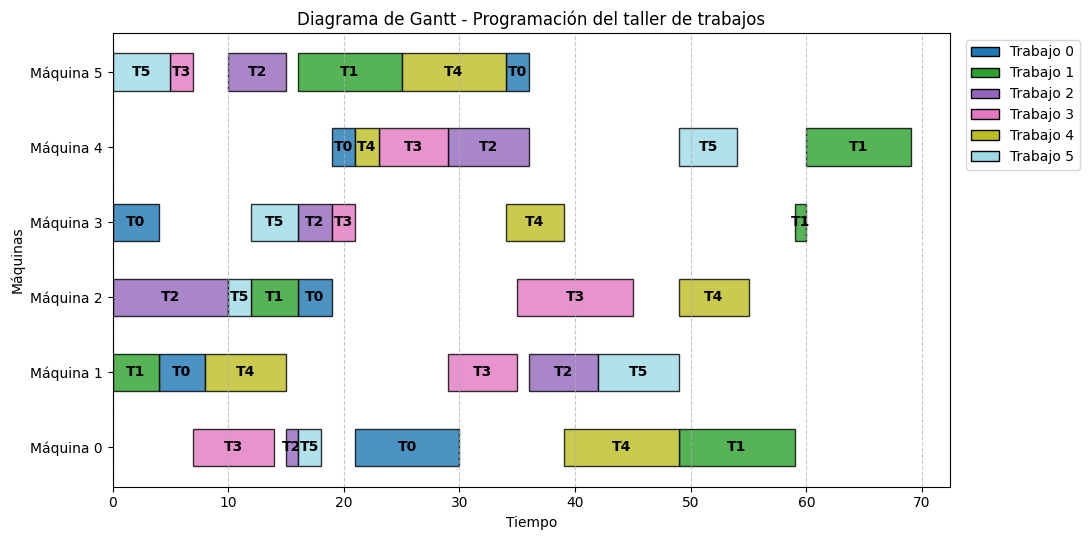

In [12]:
lns_grande.mostrar_resultados()

### Verificación de los programas obtenidos

Un diagrama de Gantt permite revisar a ojo si el programa respeta las dos condiciones del problema, que cada máquina procese una operación a la vez y que las operaciones de un trabajo sigan su orden. La función siguiente hace esa revisión sobre los tiempos de inicio guardados en cada `Trabajo`. Cuenta las parejas de operaciones que se traslapan en una misma máquina y las operaciones que empiezan antes de que termine la operación anterior de su trabajo.

In [13]:
def verificar_programa(trabajos, num_maquinas):
    """Cuenta los traslapes en las máquinas y las violaciones del orden de cada trabajo."""
    traslapes = 0
    for m in range(num_maquinas):
        intervalos = sorted((t.inicio_ops[i], t.inicio_ops[i] + d)
                            for t in trabajos
                            for i, (maq, d) in enumerate(t.operaciones) if maq == m)
        for (ini1, fin1), (ini2, fin2) in zip(intervalos, intervalos[1:]):
            if ini2 < fin1:
                traslapes += 1
    violaciones_orden = 0
    for t in trabajos:
        for i in range(1, len(t.operaciones)):
            if t.inicio_ops[i] < t.inicio_ops[i-1] + t.operaciones[i-1][1]:
                violaciones_orden += 1
    return traslapes, violaciones_orden

for nombre, modelo in [("3 x 3", lns), ("6 x 6", lns_grande)]:
    modelo.evaluar_solucion(modelo.mejor_solucion)
    traslapes, violaciones = verificar_programa(modelo.trabajos, modelo.num_maquinas)
    print(f"Instancia {nombre}: {traslapes} traslapes en máquinas, "
          f"{violaciones} operaciones que empiezan antes de terminar la anterior de su trabajo")

Instancia 3 x 3: 0 traslapes en máquinas, 0 operaciones que empiezan antes de terminar la anterior de su trabajo
Instancia 6 x 6: 0 traslapes en máquinas, 0 operaciones que empiezan antes de terminar la anterior de su trabajo


Los programas de las dos instancias cumplen las dos condiciones. Esta revisión es útil cada vez que se cambia la evaluación de un problema de programación, porque una evaluación que no respete el orden de las operaciones de cada trabajo puede informar un tiempo total de terminación menor que el de cualquier programa posible, y la búsqueda lo aceptaría como una mejora.

En la instancia de 6 trabajos, la curva de convergencia se queda plana durante tramos largos. La reparación inserta cada operación en una posición factible escogida al azar, y la mayoría de esas inserciones no acorta el programa. Una reparación que compare las posiciones, como la del taller de flujo, haría más trabajo por iteración, pero aprovecharía mejor cada una.